Lecture 12: Exploratory Data Analysis of the Tips Data Set

In [36]:
#Import necessary packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [37]:
#Read in csv data to create DataFrame
#from https://github.com/wesm/pydata-book/blob/3rd-edition/examples/tips.csv
tips = pd.read_csv('tips.csv')
tips.head()

,total_bill,tip,smoker,day,time,size
0,16.99,1.01,No,Sun,Dinner,2
1,10.34,1.66,No,Sun,Dinner,3
2,21.01,3.50,No,Sun,Dinner,3
3,23.68,3.31,No,Sun,Dinner,2
4,24.59,3.61,No,Sun,Dinner,4


In [38]:
tips.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  244 non-null    float64
 1   tip         244 non-null    float64
 2   smoker      244 non-null    object 
 3   day         244 non-null    object 
 4   time        244 non-null    object 
 5   size        244 non-null    int64  
dtypes: float64(2), int64(1), object(3)
memory usage: 11.6+ KB


In [39]:
#Peek at the end of the df
tips.tail()

,total_bill,tip,smoker,day,time,size
239,29.03,5.92,No,Sat,Dinner,3
240,27.18,2.00,Yes,Sat,Dinner,2
241,22.67,2.00,Yes,Sat,Dinner,2
242,17.82,1.75,No,Sat,Dinner,2
243,18.78,3.00,No,Thur,Dinner,2


In [40]:
#Return the number of rows and columns as a tuple
tips.shape

(244, 6)

In [41]:
#Check on the data types
tips.dtypes

total_bill    float64
tip           float64
smoker         object
day            object
time           object
size            int64
dtype: object

In [42]:
tips['day'].nunique()

4

In [43]:
tips['tip'].mean()

np.float64(2.99827868852459)

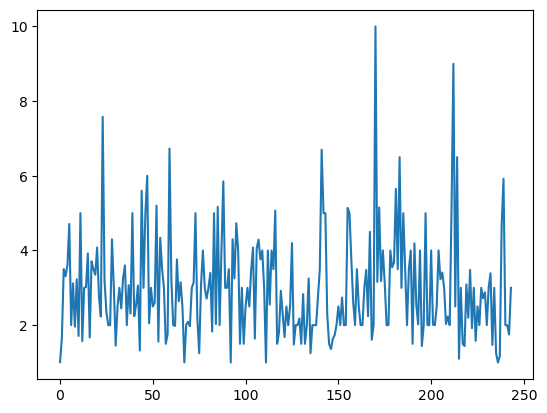

In [44]:
plt.plot(tips["tip"])

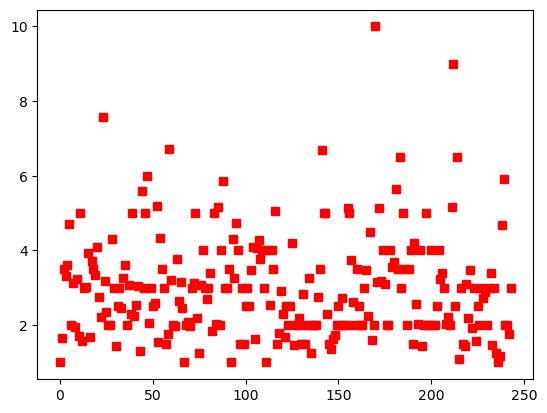

In [45]:
plt.plot(tips["tip"], 'rs')

In [46]:
#Add a column with the tip percentage
tips['percent'] = tips['tip']/tips['total_bill']*100
tips

,total_bill,tip,smoker,day,time,size,percent
0,16.99,1.01,No,Sun,Dinner,2,5.944673
1,10.34,1.66,No,Sun,Dinner,3,16.054159
2,21.01,3.50,No,Sun,Dinner,3,16.658734
3,23.68,3.31,No,Sun,Dinner,2,13.978041
4,24.59,3.61,No,Sun,Dinner,4,14.680765
...,...,...,...,...,...,...,...
239,29.03,5.92,No,Sat,Dinner,3,20.392697
240,27.18,2.00,Yes,Sat,Dinner,2,7.358352
241,22.67,2.00,Yes,Sat,Dinner,2,8.822232
242,17.82,1.75,No,Sat,Dinner,2,9.820426


In [47]:
tips['percent'].mean()

np.float64(16.08025817225047)

In [48]:
#Filter tips above 20%
twenty = tips[tips['percent'] > 20]
twenty

,total_bill,tip,smoker,day,time,size,percent
6,8.77,2.00,No,Sun,Dinner,2,22.805017
9,14.78,3.23,No,Sun,Dinner,2,21.853857
14,14.83,3.02,No,Sun,Dinner,2,20.364127
17,16.29,3.71,No,Sun,Dinner,3,22.774708
18,16.97,3.50,No,Sun,Dinner,3,20.624632
20,17.92,4.08,No,Sat,Dinner,2,22.767857
42,13.94,3.06,No,Sun,Dinner,2,21.951220
46,22.23,5.00,No,Sun,Dinner,2,22.492128
51,10.29,2.60,No,Sun,Dinner,2,25.267250
63,18.29,3.76,Yes,Sat,Dinner,4,20.557682


In [49]:
#Return how many tips are above 20%
twenty.count()

total_bill    39
tip           39
smoker        39
day           39
time          39
size          39
percent       39
dtype: int64

In [50]:
#Filter tips below 10%
ten = tips[tips['percent'] < 10]
#Return how many tips are below 10%
ten.count()

total_bill    27
tip           27
smoker        27
day           27
time          27
size          27
percent       27
dtype: int64

In [51]:
#Group by various columns and calculate aggregate means
tips.groupby('time')['percent'].mean()

time
Dinner    15.951779
Lunch     16.412793
Name: percent, dtype: float64

In [52]:
tips.groupby('smoker')['percent'].mean()

smoker
No     15.932846
Yes    16.319604
Name: percent, dtype: float64

In [53]:
tips.groupby('day')['percent'].mean()

day
Fri     16.991303
Sat     15.315172
Sun     16.689729
Thur    16.127563
Name: percent, dtype: float64

In [54]:
groupsize = tips.groupby('size')['percent'].mean()
groupsize

size
1    21.729202
2    16.571919
3    15.215685
4    14.594901
5    14.149549
6    15.622920
Name: percent, dtype: float64

In [55]:
groupsize.dtype

dtype('float64')

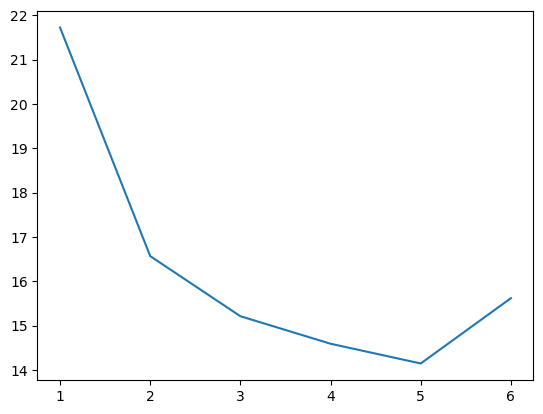

In [56]:
plt.plot(groupsize)

<Axes: xlabel='size'>

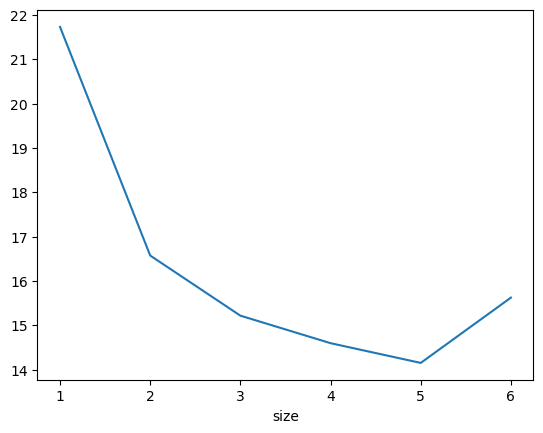

In [57]:
groupsize.plot()

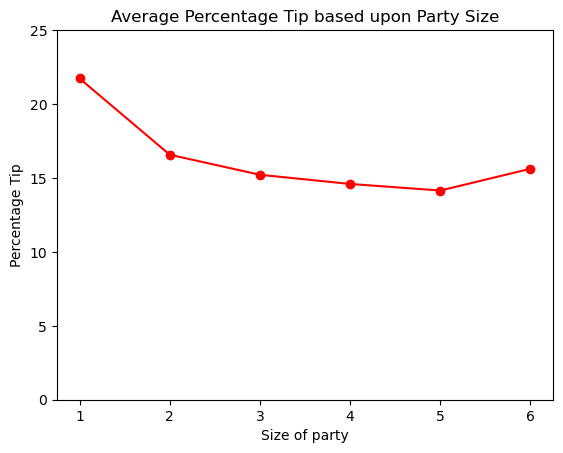

In [58]:
plt.title('Average Percentage Tip based upon Party Size')
plt.xlabel('Size of party')
plt.ylabel('Percentage Tip')
plt.ylim(ymin=0, ymax = 25)
plt.plot(groupsize, color = 'red', marker = 'o')
#plt.scatter(groupsize,'tips')

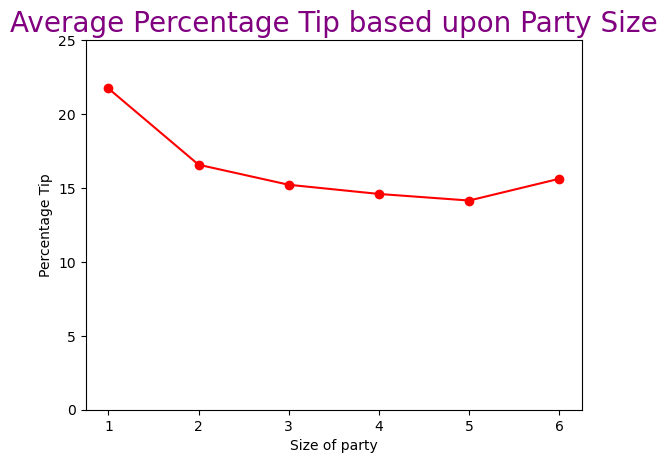

In [59]:
plt.title(label = 'Average Percentage Tip based upon Party Size', fontsize = 20, color = 'purple' )
plt.xlabel('Size of party')
plt.ylabel('Percentage Tip')
plt.ylim(ymin=0, ymax = 25)
plt.plot(groupsize, color = 'red', marker = 'o')

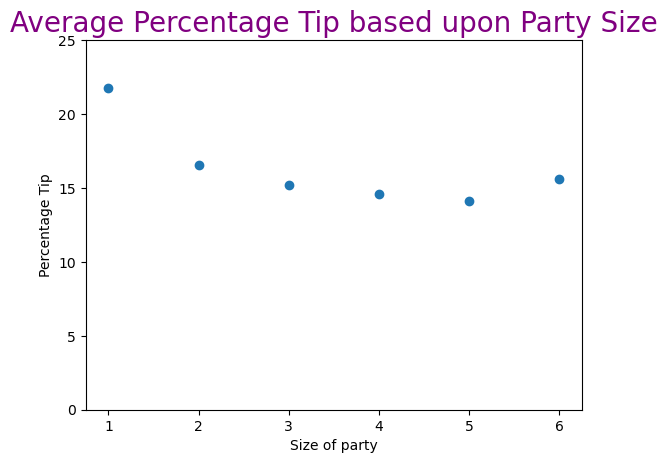

In [60]:
plt.title(label = 'Average Percentage Tip based upon Party Size', fontsize = 20, color = 'purple' )
plt.xlabel('Size of party')
plt.ylabel('Percentage Tip')
plt.ylim(ymin=0, ymax = 25)
plt.plot(groupsize, 'o')